In [1]:
## Cell 1: load data

import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

df = yf.download("SPY", start="2010-01-01", auto_adjust=True, progress=False)
prices = df["Close"].squeeze().dropna()
prices.tail()

Date
2026-11-09    752.690002
2026-11-10    749.919983
2026-11-11    759.809998
2026-11-12    757.119995
2026-11-13    754.369995
Name: SPY, dtype: float64

In [2]:
## Cell 2: strategy and backtest

fast, slow, cost_bps = 50, 200, 5

signal = (prices.rolling(fast).mean() > prices.rolling(slow).mean()).astype(int)
returns = prices.pct_change()
position = signal.shift(1).fillna(0)          # trade on yesterday's signal
trades = position.diff().abs().fillna(0)
strat = (position * returns - trades * cost_bps / 1e4).dropna()
buy_hold = returns.dropna()

Strategy    CAGR 9.1% | Sharpe 0.69 | MaxDD -33.7%
Buy & hold  CAGR 13.9% | Sharpe 0.85 | MaxDD -33.7%


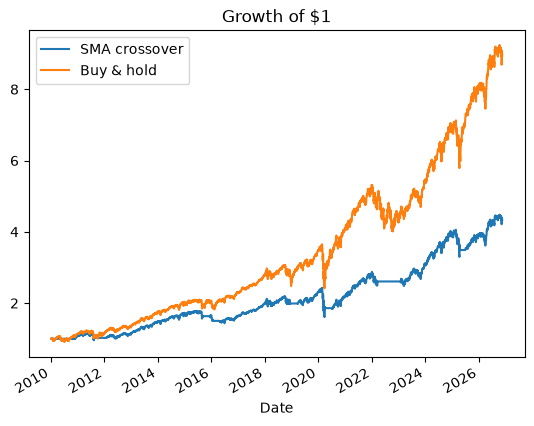

In [3]:
## Cell 3: metrics and chart

def sharpe(r): return np.sqrt(252) * r.mean() / r.std()
def max_dd(r):
    eq = (1 + r).cumprod()
    return (eq / eq.cummax() - 1).min()
def cagr(r):
    return (1 + r).cumprod().iloc[-1] ** (252 / len(r)) - 1

for name, r in [("Strategy", strat), ("Buy & hold", buy_hold)]:
    print(f"{name:11} CAGR {cagr(r):.1%} | Sharpe {sharpe(r):.2f} | MaxDD {max_dd(r):.1%}")

(1 + strat).cumprod().plot(label="SMA crossover")
(1 + buy_hold).cumprod().plot(label="Buy & hold")
plt.legend(); plt.title("Growth of $1"); plt.show()